# Literary Taste Personalization Analysis

이 노트북은 LiteraryTaste 데이터셋을 활용하여 사용자별 문학 취향을 분석하고, TransformerLens를 통해 LLM의 내부 표상을 탐색합니다.

## 목표
1. 사용자 프로필과 선호도 데이터 EDA
2. 텍스트 선호도 패턴 파악
3. LLM을 활용한 사용자 취향 예측 실험

In [1]:
# 필수 라이브러리 임포트
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import re
from collections import Counter

# 시각화 설정
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
%matplotlib inline

# 경로 설정
DATA_PATH = Path('../LiteraryTaste')
print(f"Data directory: {DATA_PATH.absolute()}")

Data directory: /Users/lucyroh/Desktop/STUDY/Data Projects/llm-personalization/notebooks/../LiteraryTaste


## 1. 데이터 로딩

In [2]:
# CSV 파일 로드
annotated_df = pd.read_csv(DATA_PATH / 'annotated_instances.csv')
preference_df = pd.read_csv(DATA_PATH / 'preference_tasks.csv')

print(f"Annotated instances shape: {annotated_df.shape}")
print(f"Preference tasks shape: {preference_df.shape}")
print(f"\nUnique users: {annotated_df['user'].nunique()}")

Annotated instances shape: (6300, 155)
Preference tasks shape: (2000, 15)

Unique users: 60


/var/folders/fv/hnh2s54s4h9_vv9q4x1rbdj40000gn/T/ipykernel_58464/3050908264.py:2: DtypeWarning: Columns (29: How frequently do you enjoy the following leisure activity?: Play sports:::Every day, 139: What is your gender?:::Non-binary, 142: Where do you live?:::Asia, 143: Where do you live?:::Oceania, 144: How would you describe your experience with fiction and poetry reading?:::No experience with fiction and poetry reading, 148: Entertaining:::Not important at all, 150: Skillful and rich language:::Not important at all, 151: How frequently do you enjoy the following leisure activity?: Watch videos (e.g., TV, YouTube, or Netflix):::Less often than once per week, 153: How frequently do you enjoy the following leisure activity?: Creative craft activity (e.g., knitting, woodworking, jewelry making):::Every day, 154: Where do you live?:::Africa) have mixed types. Specify dtype option on import or set low_memory=False.
  annotated_df = pd.read_csv(DATA_PATH / 'annotated_instances.csv')


## 2. 사용자 프로필 분석

In [3]:
# 컬럼명 파싱 - 설문 항목 추출
def parse_column_name(col):
    """설문 컬럼명에서 질문과 답변 분리"""
    if ':::' in col:
        question, answer = col.split(':::', 1)
        return question.strip(), answer.strip()
    return col, None

# 모든 컬럼 분석
column_info = [parse_column_name(col) for col in annotated_df.columns]
questions = sorted(set([q for q, a in column_info if a is not None]))

print(f"총 설문 항목 수: {len(questions)}")
print("\n주요 설문 카테고리:")
for i, q in enumerate(questions[:10], 1):
    print(f"{i}. {q}")

총 설문 항목 수: 36

주요 설문 카테고리:
1. Approximately, how many hours do you spend reading for pleasure per week?
2. Approximately, how many hours do you spend reading per week (including hours reading for pleasure)?
3. Arouses feelings
4. Based on real events
5. Challenges the reader
6. Choose specific reasons why you read (part 1)
7. Choose specific reasons why you read (part 2)
8. Choose specific reasons why you read (part 3)
9. Choose your English reading skill level.
10. Entertaining


/Users/lucyroh/Desktop/STUDY/Data Projects/llm-personalization/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/lucyroh/Desktop/STUDY/Data Projects/llm-personalization/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54840 (\N{HANGUL SYLLABLE HO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/lucyroh/Desktop/STUDY/Data Projects/llm-personalization/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/lucyroh/Desktop/STUDY/Data Projects/llm-personalization/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51025 (\N{HANGUL SYLLABLE EUNG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **

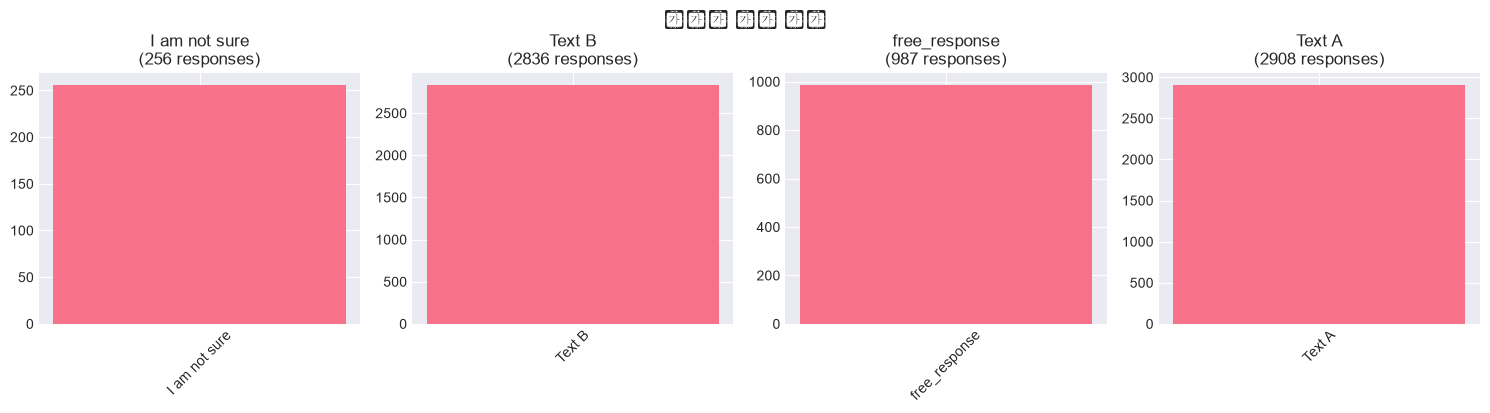

In [4]:
# 선호도 분포 확인
preference_cols = [col for col in annotated_df.columns if col.startswith('preference:::')]

fig, axes = plt.subplots(1, len(preference_cols), figsize=(15, 4))
for idx, col in enumerate(preference_cols):
    pref_type = col.split(':::')[1]
    counts = annotated_df[col].notna().sum()
    axes[idx].bar([pref_type], [counts])
    axes[idx].set_title(f"{pref_type}\n({counts} responses)")
    axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.suptitle('선호도 응답 분포', y=1.02, fontsize=14)
plt.show()

## 3. 독서 습관 분석

In [5]:
# 독서 시간 관련 컬럼 추출
reading_time_cols = [
    'Approximately, how many hours do you spend reading for pleasure per week?:::text_box',
    'Approximately, how many hours do you spend reading per week (including hours reading for pleasure)?:::text_box',
    'How many books do you read per month?:::text_box'
]

# 사용자별 독서량 데이터 추출
reading_habits = annotated_df[['user'] + reading_time_cols].copy()
reading_habits.columns = ['user', 'pleasure_hours', 'total_hours', 'books_per_month']

# 사용자별 평균 계산 (중복 제거)
reading_summary = reading_habits.groupby('user').first()

print("독서 습관 요약:")
print(reading_summary.describe())

독서 습관 요약:
       pleasure_hours  total_hours  books_per_month
count       60.000000    60.000000        60.000000
mean         8.816667    17.575000         2.758333
std          8.300483    14.687371         3.259265
min          1.000000     2.000000         0.000000
25%          3.750000     7.000000         1.000000
50%          5.000000    14.000000         2.000000
75%         10.500000    24.250000         3.000000
max         40.000000    70.000000        22.000000


## 4. 선호 장르 분석

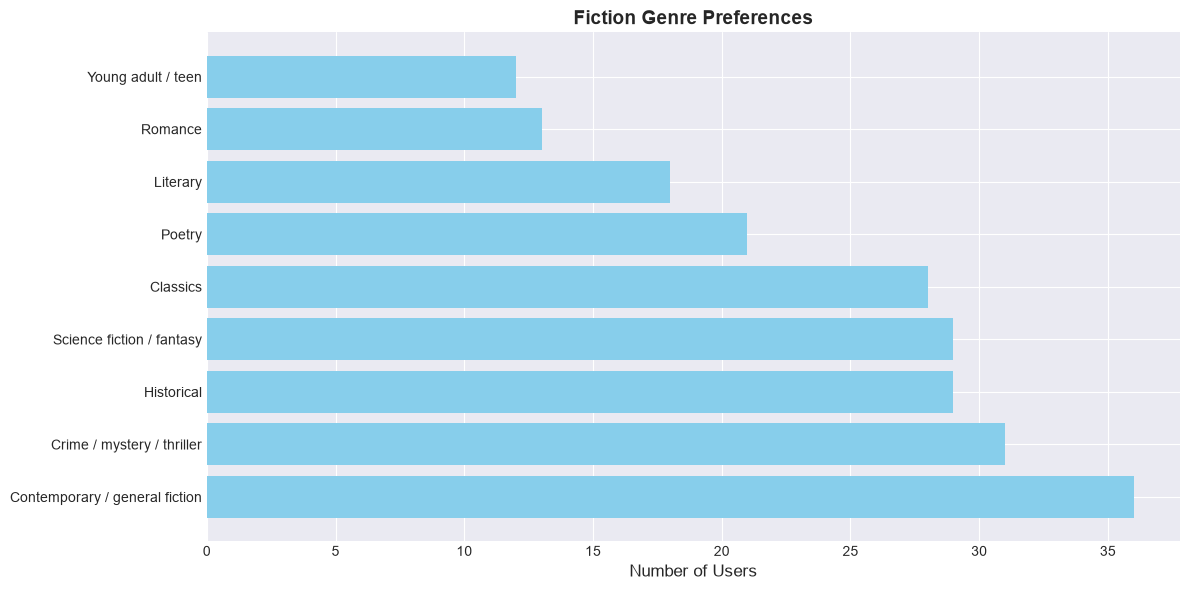


가장 인기있는 장르: Contemporary / general fiction (36 users)


In [6]:
# Fiction 장르 선호도 추출
fiction_genre_cols = [col for col in annotated_df.columns 
                      if 'Which of the following types of texts do you enjoy reading these days? (among fiction):::' in col
                      and 'free_response' not in col
                      and 'Others' not in col]

# 장르명만 추출
fiction_genres = [col.split(':::')[-1] for col in fiction_genre_cols]

# 각 장르별 선호 사용자 수 계산
genre_counts = {}
for col, genre in zip(fiction_genre_cols, fiction_genres):
    genre_counts[genre] = annotated_df[col].notna().sum()

# 시각화
plt.figure(figsize=(12, 6))
sorted_genres = sorted(genre_counts.items(), key=lambda x: x[1], reverse=True)
genres, counts = zip(*sorted_genres)

plt.barh(genres, counts, color='skyblue')
plt.xlabel('Number of Users', fontsize=12)
plt.title('Fiction Genre Preferences', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n가장 인기있는 장르: {sorted_genres[0][0]} ({sorted_genres[0][1]} users)")

## 5. 텍스트 쌍 선호도 분석

In [7]:
# HTML에서 텍스트 추출 함수
def extract_texts_from_html(html_str):
    """HTML에서 Text A와 Text B 추출"""
    if pd.isna(html_str):
        return None, None
    
    # 간단한 정규식 파싱 (실제로는 BeautifulSoup 권장)
    text_a_match = re.search(r'<h3>Text A</h3>.*?<p[^>]*>(.*?)</p>', html_str, re.DOTALL)
    text_b_match = re.search(r'<h3>Text B</h3>.*?<p[^>]*>(.*?)</p>', html_str, re.DOTALL)
    
    text_a = re.sub(r'<.*?>', '', text_a_match.group(1)).strip() if text_a_match else None
    text_b = re.sub(r'<.*?>', '', text_b_match.group(1)).strip() if text_b_match else None
    
    return text_a, text_b

# 선호도 분석을 위한 데이터 구성
preference_data = []

for _, row in annotated_df.iterrows():
    text_a, text_b = extract_texts_from_html(row['displayed_text'])
    
    if text_a and text_b:
        pref = None
        if pd.notna(row.get('preference:::Text A')):
            pref = 'A'
        elif pd.notna(row.get('preference:::Text B')):
            pref = 'B'
        elif pd.notna(row.get('preference:::I am not sure')):
            pref = 'Unsure'
        
        preference_data.append({
            'user': row['user'],
            'instance_id': row['instance_id'],
            'text_a': text_a,
            'text_b': text_b,
            'preference': pref,
            'text_a_len': len(text_a),
            'text_b_len': len(text_b)
        })

pref_df = pd.DataFrame(preference_data)
print(f"\n총 선호도 판단 수: {len(pref_df)}")
print(f"선호도 분포:\n{pref_df['preference'].value_counts()}")


총 선호도 판단 수: 6000
선호도 분포:
preference
A         2908
B         2836
Unsure     256
Name: count, dtype: int64


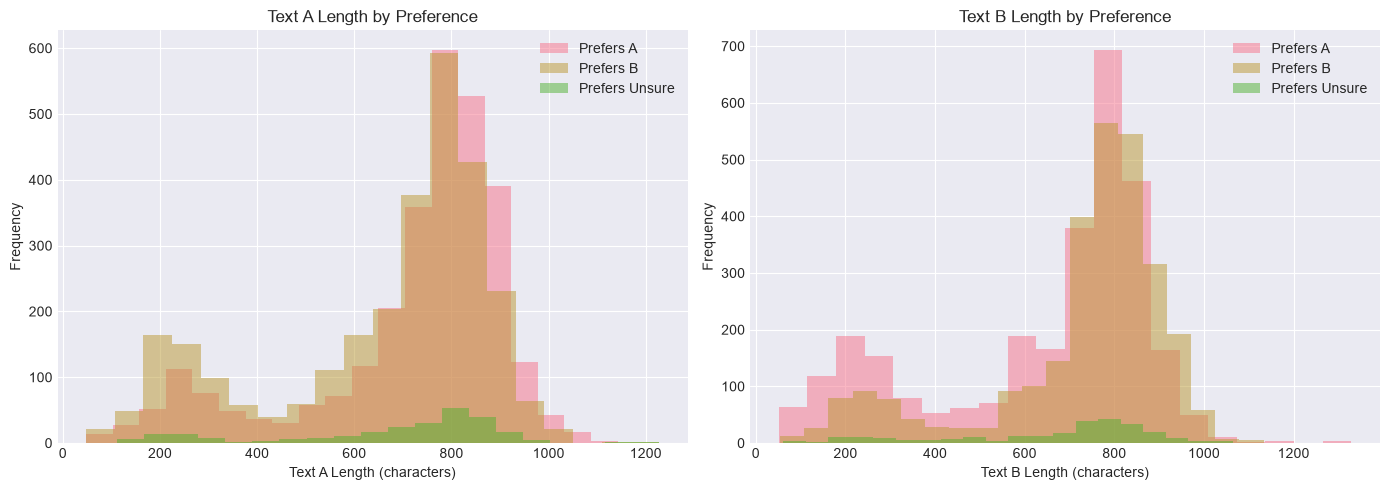

In [8]:
# 텍스트 길이와 선호도 관계
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Text A 길이 분포
for pref in ['A', 'B', 'Unsure']:
    data = pref_df[pref_df['preference'] == pref]['text_a_len']
    if len(data) > 0:
        axes[0].hist(data, alpha=0.5, label=f'Prefers {pref}', bins=20)
axes[0].set_xlabel('Text A Length (characters)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Text A Length by Preference')
axes[0].legend()

# Text B 길이 분포
for pref in ['A', 'B', 'Unsure']:
    data = pref_df[pref_df['preference'] == pref]['text_b_len']
    if len(data) > 0:
        axes[1].hist(data, alpha=0.5, label=f'Prefers {pref}', bins=20)
axes[1].set_xlabel('Text B Length (characters)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Text B Length by Preference')
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. 사용자 프로필 클러스터링 준비

다음 단계에서는 사용자 특성을 기반으로 클러스터링을 수행하고, 각 클러스터의 텍스트 선호 패턴을 분석할 예정입니다.

In [9]:
# 사용자별 특성 벡터 생성 함수
def create_user_feature_vector(user_id, df):
    """사용자별 특성 벡터 생성"""
    user_data = df[df['user'] == user_id].iloc[0]
    
    features = {}
    
    # 장르 선호도 (이진 벡터)
    for col in fiction_genre_cols:
        genre = col.split(':::')[-1]
        features[f'genre_{genre}'] = 1 if pd.notna(user_data[col]) else 0
    
    # 여가 활동 빈도
    leisure_cols = [col for col in df.columns if 'How frequently do you enjoy' in col]
    for col in leisure_cols:
        if pd.notna(user_data[col]):
            activity = col.split('?:')[1].split(':::')[0] if '?:' in col else 'unknown'
            freq = col.split(':::')[-1]
            features[f'leisure_{activity}_{freq}'] = 1
    
    return features

# 샘플 사용자 특성 벡터 생성
sample_users = annotated_df['user'].unique()[:5]
print("샘플 사용자 특성:")
for user in sample_users:
    features = create_user_feature_vector(user, annotated_df)
    print(f"\nUser {user}: {sum(features.values())} active features")

샘플 사용자 특성:

User 604221D0: 0 active features

User 75D1DD21: 0 active features

User 3491C127: 0 active features

User 084221A7: 0 active features

User C3398E0A: 0 active features


## 7. 다음 단계: TransformerLens 통합

### 계획
1. **모델 선택**: GPT-2 또는 작은 LLaMA 모델 로드
2. **프롬프트 설계**: 사용자 프로필 + 텍스트 쌍 → 선호도 예측
3. **활성화 추출**: 각 레이어에서 hidden states 추출
4. **프로빙**: 사용자 특성이 어느 레이어에서 인코딩되는지 분석
5. **스티어링**: 특정 사용자 취향으로 모델 조정

이 부분은 다음 셀에서 구현합니다.

In [10]:
# TransformerLens 설치 (필요시)
# !pip install transformer-lens

# TODO: 다음 노트북 또는 섹션에서 구현
# from transformer_lens import HookedTransformer
# model = HookedTransformer.from_pretrained("gpt2-small")

print("TransformerLens 통합은 다음 단계에서 진행됩니다.")
print("현재까지 EDA 완료!")

TransformerLens 통합은 다음 단계에서 진행됩니다.
현재까지 EDA 완료!


## Summary

이 노트북에서 수행한 작업:
- ✅ LiteraryTaste 데이터 로드 및 구조 파악
- ✅ 사용자 프로필 분석 (독서 습관, 장르 선호도)
- ✅ 텍스트 쌍 선호도 패턴 탐색
- ✅ 사용자 특성 벡터화 준비

다음 노트북에서:
- TransformerLens를 활용한 모델 분석
- 레이어별 활성��� 패턴 추출
- Probing을 통한 사용자 표상 위치 탐색